# qDRIFT: circuits and averaged channels

This notebook separates a sampled unitary trajectory from the averaged channel. The recorded one/two-spin examples use time 1/2,8 term exponentials and32 fresh trials each. Readout samples are generated classically from ideal circuit probabilities. Physical costs and formalization remain planned.

In [1]:
from pathlib import Path
import sys, os, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, SVG
root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
if (root / "src").is_dir():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import qdrift as qd
    data = root / "assets/generated/simulation/qdrift"
else:
    sys.path.insert(0, str(root))
    import qdrift as qd
    data = root
manifest = json.loads((data / "manifest.json").read_text())
for name, record in manifest["files"].items():
    content = (data / name).read_bytes()
    assert len(content) == record["bytes"]
    assert hashlib.sha256(content).hexdigest() == record["sha256"]
assert manifest["source_sha256"]["src/openquantum/simulation/qdrift.py"] == hashlib.sha256(Path(qd.__file__).read_bytes()).hexdigest()
assert manifest["native_estimator_calls"] == 0
manifest["status"], manifest["independent_seed_trajectories_recorded"]

('generated_and_ideal_checked', 64)

## Complete small circuit

Every exported measured trial contains initial resets, explicit basis preparation, all sampled exponentials and final Z readout. The first one-spin seed below is from the recorded 32-trial study.

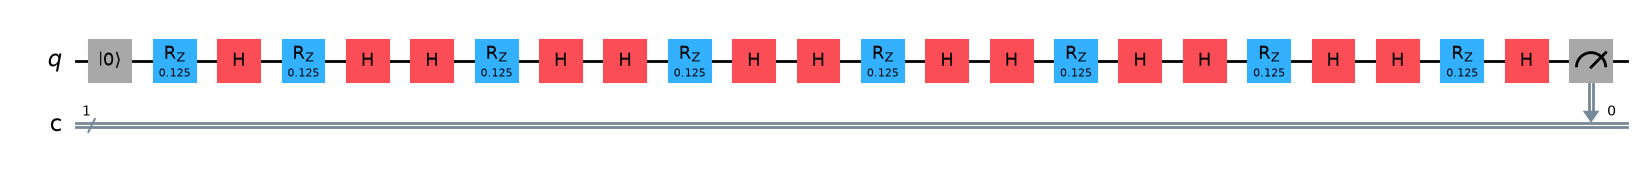

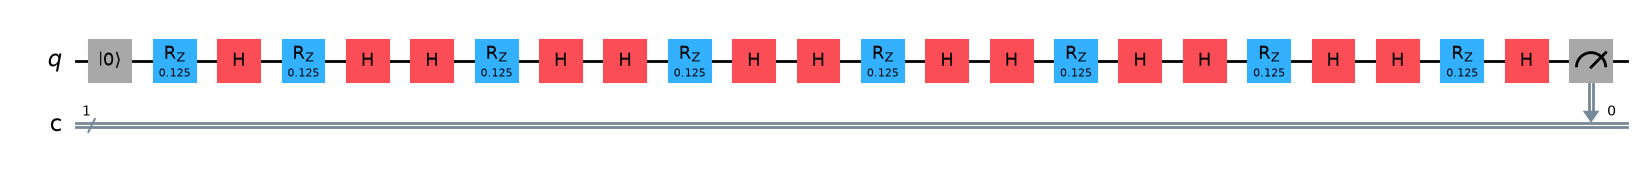

In [2]:
one = qd.Hamiltonian.from_terms(1, [("7/10", "X"), ("3/10", "Z")])
one_saved = json.loads((data / "one-spin/study.json").read_text())
seed = one_saved["records"][0]["trajectory_seed"]
qd.qdrift_circuit(one, "1/2", 8, seed, measure=True).draw(output="mpl", fold=35)

## Averaged-channel reference

The single-step mixture is raised to N. Matrix-unit checks exercise the entire channel. HS-induced superoperator error, Choi trace distance and a fixed-input observable bias are different metrics; none is a diamond norm.

In [3]:
two = qd.chain_hamiltonian(2)
check = qd.channel_comparison(two, "1/2", 8)
assert check["channel_diagnostics"]["trace_preservation_max_error"] < 1e-11
assert check["channel_diagnostics"]["normalized_choi_min_eigenvalue"] > -1e-11
check

{'steps': 8,
 'time_exact': '1/2',
 'hs_induced_superoperator_error': 0.24703807694460547,
 'normalized_choi_trace_distance': 0.1106885161438995,
 'fixed_input_trace_distance': 0.08982166113955413,
 'ensemble_observable': 0.7257996384821523,
 'exact_observable': 0.7836360900724649,
 'observable_bias': 0.05783645159031253,
 'metric_scope': 'HS-induced2->2 superoperator norm, normalized Choi and fixed-input diagnostics; none is a computed diamond norm or certified floating-point bound',
 'channel_diagnostics': {'spanning_matrix_units': 16,
  'trace_preservation_max_error': 4.441719407144243e-16,
  'hermiticity_preservation_max_error': 3.8051957856957015e-16,
  'unitality_error': 6.475399281240404e-16,
  'normalized_choi_trace': 0.9999999999999998,
  'normalized_choi_hermitian_error': 1.966296485418597e-16,
  'normalized_choi_min_eigenvalue': -7.503975975180898e-17,
  'scope': 'Numerical diagnostics of an analytically CP/TP mixture of ideal unitaries; no formal or interval certificate'}}

,case,qubits,lambda_exact,steps,trajectories,ensemble_Z0,exact_Z0,ensemble_bias,sample_mean,hoeffding_radius,hs_induced_superoperator_error
0,one-spin,1,1,8,32,0.756404,0.766615,0.010211,0.875,0.480161,0.025915
1,two-spin,2,12/5,8,32,0.725800,0.783636,0.057836,0.500,0.480161,0.247038


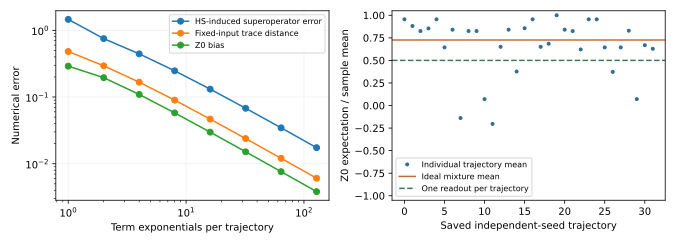

In [4]:
display(pd.read_csv(data / "summary.csv"))
display(SVG(filename=str(data / "two-spin/channel-and-samples.svg")))

## Reproduce a fresh bounded empirical study

This four-trial check redraws a complete trajectory and full readout for each trial. Its deterministic PRNG streams do not prove independence or validate Hoeffding coverage. The canonical 64-trial archive above remains unchanged.

In [5]:
small = qd.empirical_study(one, "1/2", 8, trajectories=4, master_seed=19)
assert len(small["records"]) == 4
assert small["complete_workload"]["term_draws"] == 32
assert small["complete_workload"]["fresh_preparations"] == 4
small["sample_mean"], small["ensemble_reference"]["ensemble_observable"], small["complete_workload"]

(1.0,
 0.7564041065849472,
 {'fresh_preparations': 4,
  'term_draws': 32,
  'primitive_counts': {'rz': 32, 'h': 38, 'reset': 4, 'measure': 4},
  'zero_state_resets': 4,
  'final_measurements': 4,
  'readout_samples_used': 4,
  'rational_weight_table_builds': 1,
  'classical_objective_scores': 4})

## Generate a larger circuit without a simulator

Circuit construction and dense/channel simulation have independent guards. This 16-spin export is constructed only; no large quantum-state array is allocated.

In [6]:
large_hamiltonian = qd.chain_hamiltonian(16)
large = qd.qdrift_circuit(large_hamiltonian, "1/2", 16, seed=7, measure=True)
large.num_qubits, dict(large.count_ops()), large.depth()

(16, {'cx': 20, 'reset': 16, 'rz': 16, 'measure': 16, 'h': 12}, 23)

## Optional local controls

Saved circuit/plot outputs serve the static site. The optional controls below require a local or Binder kernel; they do not add a maintained public server.

In [7]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    @widgets.interact(steps=widgets.IntSlider(value=8, min=1, max=64), seed=widgets.Dropdown(options=[7, 19, 41]))
    def explore(steps, seed):
        display(qd.qdrift_circuit(one, "1/2", steps, seed, measure=True).draw(output="mpl", fold=35))
        display(qd.channel_comparison(one, "1/2", steps))
else:
    print("Static build: optional kernel controls omitted.")

Static build: optional kernel controls omitted.


## Resource and proof scope

The saved ledgers include all actual preparation/reset, parity/basis rotations, term draws and measured-trial readout. Scalar angle conversion and source counts precede Clifford+T synthesis, error correction, factories and physical scheduling. These later costs are pending. The local numerical channel/circuit checks are not a mechanized proof or a claim of quantum advantage.